## Imports

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
import multiprocessing

from textblob import TextBlob
import nltk
from nltk.stem.porter import *
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
from sklearn.preprocessing import LabelEncoder

from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.decomposition import PCA
from gensim.models import Word2Vec

import re
import string
from dateutil.relativedelta import relativedelta

import math

import os
from scipy.stats import f_oneway
from datetime import datetime
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


## Get raw files

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
folder_path = f'/content/drive/MyDrive/CS5228 Files'
# folder_path = f'cs5228-project-data'

# List files in the folder
if os.path.exists(folder_path):
    files = os.listdir(folder_path)
    print(f'Files in the folder: {files}')
else:
    print(f'Folder path {folder_path} does not exist.')

Files in the folder: ['example-submission.csv', 'test.csv', 'train.csv', 'CS5228_Model_Playbook.ipynb', 'test.gsheet', 'Models', 'CS5228_Models_Kavish.ipynb', 'indiv_models_ and combined ensemble.ipynb', 'CS5228_NN_Models.ipynb', 'CS5228_Data_Preprocessing.ipynb']


In [ ]:
# Define file paths
train_file = os.path.join(folder_path, 'train.csv')
test_file = os.path.join(folder_path, 'test.csv')
submission_file = os.path.join(folder_path, 'example-submission.csv')

# Load CSV files into DataFrames
train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)
submission_df = pd.read_csv(submission_file)

In [ ]:
# Add a source identifier and reset index to keep original indices as a column
train_df['source'] = 'train'
test_df['source'] = 'test'

# Combine the DataFrames, resetting the index to keep original index as a column
combined_df = pd.concat([train_df.reset_index(), test_df.reset_index()], ignore_index=True)

# Rename original index column for clarity
combined_df = combined_df.rename(columns={'index': 'original_index'})

## Identify Data fields

In [ ]:
target = "price"
numerical = [
    "listing_id", "manufactured", "original_reg_date", "reg_date", "curb_weight", "power", "engine_cap", "no_of_owners",
    "depreciation", "coe", "road_tax", "dereg_value", "mileage", "omv", "arf", "lifespan", "indicative_price"
]
categorical = [
    "title", "make", "model", "description", "type_of_vehicle", "category", "transmission",
    "fuel_type", "opc_scheme", "eco_category", "features", "accessories"
]

## Data correlation analysis

In [ ]:
categorical_df = combined_df[categorical + ["price"]]
# remove opc, fuel_type, and eco since almost all cols are empty for initial analysis
wo_opc_eco_cat = categorical_df.drop(columns=["opc_scheme", "eco_category", "fuel_type"])
wo_opc_eco_cat = wo_opc_eco_cat.dropna()

In [ ]:
results = {}

# Perform ANOVA for each categorical variable
for cat_var in wo_opc_eco_cat.columns:
    if cat_var == "price":
        continue
    # Group the target variable by the categorical variable
    groups = [wo_opc_eco_cat['price'][wo_opc_eco_cat[cat_var] == category] for category in wo_opc_eco_cat[cat_var].unique()]

    # Perform One-Way ANOVA
    # print(cat_var)
    # print(groups)
    # print()
    f_stat, p_value = f_oneway(*groups)

    # Store results
    results[cat_var] = {'F-statistic': f_stat, 'p-value': p_value}

# Convert results to DataFrame for better readability
anova_results_df = pd.DataFrame(results).T
print(anova_results_df)

KeyboardInterrupt: 

## Data Preprocessing for manufactured data field

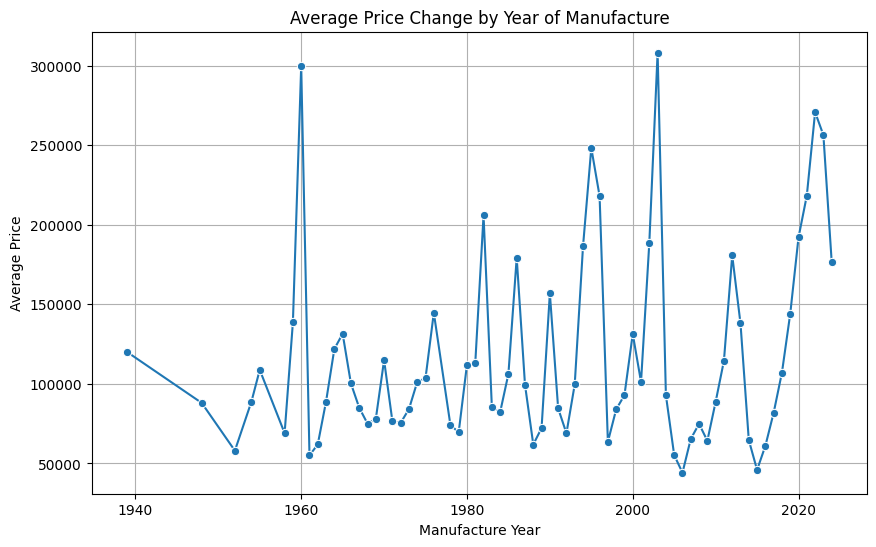

In [ ]:
testing_potential_bins = train_df.copy()
testing_potential_bins['manufactured'] = pd.to_datetime(testing_potential_bins['manufactured'], format='%Y', errors='coerce')

# Extract year as an integer
testing_potential_bins['year'] = testing_potential_bins['manufactured'].dt.year

# Group by year and calculate the average price for each year
yearly_avg_price = testing_potential_bins.groupby('year')['price'].mean().reset_index()

# Plot the data
plt.figure(figsize=(10, 6))
sns.lineplot(data=yearly_avg_price, x='year', y='price', marker='o')
plt.title("Average Price Change by Year of Manufacture")
plt.xlabel("Manufacture Year")
plt.ylabel("Average Price")
plt.grid(True)
plt.show()

In [ ]:
# Work on a slice of the DataFrame
df_slice = combined_df[['title', 'manufactured', 'price']].copy()

# Convert 'manufactured' to datetime format
df_slice['manufactured'] = pd.to_datetime(df_slice['manufactured'], format='%Y', errors='coerce')

# Impute missing manufacture date values by grouping by title and taking the median year
overall_median = df_slice['manufactured'].median()
df_slice['manufactured'] = df_slice.groupby('title')['manufactured'].transform(
    lambda x: x.fillna(x.median()) if not x.isna().all() else x.fillna(overall_median)
)

# Calculate correlation between age and price
df_slice['vehicle_age'] = datetime.now().year - df_slice['manufactured'].dt.year
correlation = df_slice['vehicle_age'].corr(df_slice['price'])
print(f'Correlation between vehicle age and price: {correlation}')

# Was considering creating 5 year bins but seems redundant from the plot above (Also might cause unintended interactions)

Correlation between vehicle age and price: -0.2030501664689336


## Add features derived from manufactured data field

In [ ]:
combined_df['feature_manufactured_vehicle_age'] = df_slice['vehicle_age']

## Data Preprocessing for engine_cap

In [ ]:
is_electric = combined_df['title'].str.contains('electric', case=False, na=False) | \
              combined_df['category'].str.contains('electric', case=False, na=False)

# Exclude hybrids
is_electric = is_electric & ~combined_df['title'].str.contains('hybrid', case=False, na=False) & \
              ~combined_df['category'].str.contains('hybrid', case=False, na=False)

engines_are_electric = combined_df['engine_cap'][is_electric]
print("Cars that have electric but also have engine_cap\n", combined_df.iloc[engines_are_electric[engines_are_electric.notna()].index].engine_cap)
print("Cars that have 0 engine_cap\n", combined_df[combined_df.engine_cap <= 0][["title", "engine_cap"]])


# As you can see all cars that have a missing engine_caps are electric and the dataset already implicitly sets such cars to have a 0 engine cap
# Thus what we will do is to set the engine cap to be 0 for electric cars and the mean otherwise
mean_engine_cap = combined_df['engine_cap'].mean()
combined_df['feature_engine_cap'] = np.where(is_electric, 0, combined_df['engine_cap'].fillna(mean_engine_cap))

# Also we will create a new column to indicate electric vehicles (0 = not electric, 1 = electric) as an additional feature in case
combined_df['feature_is_electric'] = np.where(is_electric, 1, 0)

Cars that have electric but also have engine_cap
 3104     0.0
24745    0.0
Name: engine_cap, dtype: float64
Cars that have 0 engine_cap
                          title  engine_cap
3104     ORA Good Cat Electric         0.0
24745  MG 5 Electric Exclusive         0.0


## Data Preprocessing for curb_weight and power data fields

In [ ]:
# Function to predict missing values for a target column using given predictors
def impute_missing_values(df, target, numerical_predictors, categorical_predictors, k):
    # Split data into rows where target is missing and not missing
    missing_target_df = df[df[target].isna()]
    non_missing_target_df = df[~df[target].isna()]

    if len(non_missing_target_df) == 0:  # No available data for training
        print(f"No data available to train for {target}")
        return df

    # Separate numerical and categorical columns
    X_train = non_missing_target_df[numerical_predictors + categorical_predictors]
    y_train = non_missing_target_df[target]

    # Make pipeline with imputation, encoding, and KNN model
    numerical_transformer = SimpleImputer(strategy='mean')  # Use mean for numerical columns
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),  # Use most frequent for categorical columns
        ('onehot', OneHotEncoder(handle_unknown='ignore'))     # One-hot encode categorical features
    ])

    # Combine numerical and categorical transformers
    preprocessor = ColumnTransformer(transformers=[
        ('num', numerical_transformer, numerical_predictors),
        ('cat', categorical_transformer, categorical_predictors)
    ])

    # Create a pipeline that combines preprocessing and the KNN model
    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', KNeighborsRegressor(n_neighbors=k))
    ])

    # Train model using rows where target is not missing
    model_pipeline.fit(X_train, y_train)

    # Predict for rows where target is missing
    X_missing = missing_target_df[numerical_predictors + categorical_predictors]
    predicted_values = model_pipeline.predict(X_missing)

    # Fill in the missing values with predictions
    df.loc[df[target].isna(), target] = predicted_values
    return df

curb_weight_numerical = ['engine_cap', 'road_tax']
curb_weight_categorical = ['make', 'type_of_vehicle', 'model']

power_numerical = ['engine_cap', 'depreciation', 'road_tax', 'omv', 'arf']
power_categorical = ['make', 'type_of_vehicle', 'model']

df_slice = combined_df.copy()

# k values determined with elbow method previously
df_slice = impute_missing_values(df_slice, 'curb_weight', curb_weight_numerical, curb_weight_categorical, 4)
df_slice = impute_missing_values(df_slice, 'power', power_numerical, power_categorical, 7)

## Add features from imputed curb_weight and power

In [ ]:
combined_df['feature_curb_weight_imputed'] = df_slice['curb_weight']
combined_df['feature_power_imputed'] = df_slice['power']

## Data Preprocessing for make and model data field

In [ ]:
train_df = combined_df[combined_df['source'] == 'train']
test_df = combined_df[combined_df['source'] == 'test']

In [ ]:
# Get all unique make values and store them in a dict, excluding NaNs
unique_makes = train_df['make'].dropna().unique()
imputing_make = combined_df[['make', 'title', 'price']].copy()

# Impute make values using dict; if not in dict, make it "other"
def impute_make(row):
    isrow19 = row.name == 19
    if pd.isna(row['make']):
        if pd.notna(row['title'].lower()):  # Check if title is not NaN
            title_str = str(row['title']).lower()  # Convert to string for safe comparison
            if isinstance(title_str, str):
                for make in unique_makes:
                    if make in title_str:
                        return make
    if pd.isna(row['make']):
      return 'other'
    else:
      return row['make']

combined_df['make_imputed'] = imputing_make.apply(impute_make, axis=1)

In [ ]:
combined_df['make_model'] = combined_df["make_imputed"] + '_' + combined_df["model"]
train_df = combined_df[combined_df['source'] == 'train']

In [ ]:
# Get the unique 'model_make' values from the training set
all_make_model = train_df['make_model'].unique()
all_make = train_df['make_imputed'].unique()

# Replace values in 'model_make' in the combined set that are not in the training set's unique values with 'other'
combined_df['make_model'] = combined_df['make_model'].apply(lambda x: x if x in all_make_model else 'other')
combined_df['make_imputed'] = combined_df['make_imputed'].apply(lambda x: x if x in all_make else 'other')

## One Hot Encoding for categorical make feature

In [ ]:
from scipy import stats
import statsmodels.api as sm

# (0.5% of dataset size is 125)
def analyze_make_significance(data, make_col='make_imputed', price_col='price', min_samples=125, significance_level=0.05):
    results = {}

    # Initial filtering based on sample size
    make_counts = data[make_col].value_counts()
    makes_with_sufficient_samples = make_counts[make_counts >= min_samples].index

    # Perform one-way ANOVA
    base_price_mean = data[price_col].mean()
    make_stats = []

    for make in makes_with_sufficient_samples:
        make_data = data[data[make_col] == make][price_col]

        # Calculate statistical measures
        t_stat, p_value = stats.ttest_1samp(make_data, base_price_mean)
        effect_size = (make_data.mean() - base_price_mean) / data[price_col].std()

        make_stats.append({
            'make': make,
            'sample_size': len(make_data),
            't_statistic': abs(t_stat),
            'p_value': p_value,
            'effect_size': abs(effect_size),
            'mean_price': make_data.mean(),
            'price_std': make_data.std()
        })

    make_stats_df = pd.DataFrame(make_stats)

    # Identify significant makes
    significant_makes = make_stats_df[
        (make_stats_df['p_value'] < 0.05) &
        (make_stats_df['effect_size'] > 0.1)
    ]['make'].tolist()

    # Create pruned dataset with other category
    data_pruned = data.copy()
    data_pruned[make_col] = data_pruned[make_col].apply(
        lambda x: x if x in significant_makes else 'other'
    )

    # Validate the pruning through model comparison
    # Create OHE versions of both original and pruned datasets
    X_original = pd.get_dummies(data[make_col], prefix='make').astype(int)
    X_pruned = pd.get_dummies(data_pruned[make_col], prefix='make').astype(int)

    # Fit linear models
    y = data[price_col]
    model_original = sm.OLS(y, sm.add_constant(X_original)).fit()
    model_pruned = sm.OLS(y, sm.add_constant(X_pruned)).fit()

    # Prepare results
    results['make_stats_df'] = make_stats_df
    results['significant_makes'] = significant_makes
    results['original_features'] = len(X_original.columns)
    results['pruned_features'] = len(X_pruned.columns)
    results['original_r2'] = model_original.rsquared
    results['pruned_r2'] = model_pruned.rsquared
    results['make_statistics'] = make_stats_df
    results['price_variation_explained'] = {
        'original': model_original.rsquared,
        'pruned': model_pruned.rsquared,
        'difference': model_original.rsquared - model_pruned.rsquared
    }

    return results

In [ ]:
train_df = combined_df[combined_df['source'] == 'train']

In [ ]:
# List of specific values to one-hot encode
# Chosen using importance in variance explanation
values_to_ohe = analyze_make_significance(train_df)['significant_makes']

# Create a one-hot encoded DataFrame for only the specified values
ohe_df = pd.get_dummies(combined_df['make_imputed'])[values_to_ohe]

# Rename the columns if needed, e.g., to color_red and color_blue
ohe_df.columns = [f'feature_make_{val}' for val in values_to_ohe]
ohe_df.head(3)

,feature_make_toyota,feature_make_mercedes-benz,feature_make_honda,feature_make_nissan,feature_make_volkswagen,feature_make_mazda,feature_make_mitsubishi,feature_make_hyundai,feature_make_kia,feature_make_porsche,...,feature_make_mini,feature_make_suzuki,feature_make_citroen,feature_make_land rover,feature_make_renault,feature_make_opel,feature_make_peugeot,feature_make_maserati,feature_make_ferrari,feature_make_bentley
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
1,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
# Combine the original DataFrame with the new one-hot columns
combined_df = pd.concat([combined_df, ohe_df], axis=1)

## Target Encoding

In [ ]:
global_mean = train_df['price'].mean()
global_std = train_df['price'].std()
df_slice = combined_df[["price", "make_imputed", "make_model"]]

In [ ]:
# Group statistics
make_stats = train_df.groupby('make_imputed').agg({
    'price': ['count', 'mean']
}).reset_index()
make_stats
make_stats.columns = ['make_imputed', 'make_count', 'make_mean']

new_row = {'make_imputed': 'other', 'make_count': 0, 'make_mean': global_mean}
make_stats.loc[len(make_stats)] = new_row

# ---------

make_model_stats = train_df.groupby('make_model').agg({
    'price': ['count', 'mean']
}).reset_index()
make_model_stats.columns = ['make_model', 'make_model_count', 'make_model_mean']

new_row = {'make_model': 'other', 'make_model_count': 0, 'make_model_mean': global_mean}
make_model_stats.loc[len(make_model_stats)] = new_row

In [ ]:
df_slice = df_slice.merge(make_stats, on='make_imputed', how='left')
df_slice = df_slice.merge(make_model_stats, on='make_model', how='left')

In [ ]:
make_weight = (1 - np.exp(-0.02 * (df_slice.make_count-1))) / (1 - np.exp(-0.02 * (125-1)))
make_model_weight = (1 - np.exp(-0.4 * (df_slice.make_model_count-1))) / (1 - np.exp(-0.4 * (125-1)))
df_slice['make_target_encoded'] = df_slice['make_mean'] * make_weight + (global_mean) * (1 - make_weight)
df_slice['feature_make_model_target_encoded'] = df_slice['make_model_mean'] * make_model_weight + df_slice['make_target_encoded'] * (1 - make_model_weight)

In [ ]:
correlation = df_slice['feature_make_model_target_encoded'].corr(df_slice['price'])
print(f'Correlation between target encoded prices and actual prices: {correlation}')

Correlation between target encoded prices and actual prices: 0.8647367775472534


In [ ]:
combined_df['feature_make_model_target_encoded'] = df_slice['feature_make_model_target_encoded']

## Data preprocessing to extract information from title data field

In [ ]:
train_coe = combined_df['title'].str.extract(r'(COE.*till.*\d*/\d*)')
new_coe_train = combined_df['title'].str.extract(r'(\d*-yr COE)')
train_engine_type = combined_df['title'].str.extract(r'(\d+\.\d+A?)')
train_make = combined_df['title'].str.extract(r'(^\S*)')

train_engine_type[0] = train_engine_type[0].str.rstrip('A')
train_engine_type[0] = train_engine_type[0].astype(float)

combined_df['engine_type'] = train_engine_type[0]

make_replace = {'alfa': 'alfa romeo', 'aston': 'aston martin', 'golden':  'golden dragon', 'land': 'land rover'}
train_make[0] = train_make[0].str.lower()
train_make[0] = train_make[0].replace(make_replace)

idx = combined_df['make'].isnull().tolist()
idx = [i for i in range(len(idx)) if idx[i] == True]
combined_df['make'].iloc[idx] = train_make[0].iloc[idx]

# low mileage # 1 or 0
# 1 year warranty # number of warranty
train_warranty = combined_df['description'].str.extract(r'(\d+ years* warranty)')

train_warranty_extend = combined_df['description'].str.extract(r'(\d+ years* extended)')

train_low_mileage = combined_df['description'].str.extract(r'(low mileage)')

combined_df['feature_low_mileage'] = pd.Series([0 for _ in range(len(combined_df))])

combined_df['feature_low_mileage'].iloc[train_low_mileage.dropna().index.tolist()] = pd.Series([1 for _ in range(len(train_low_mileage.dropna()))])

<ipython-input-103-51ea9d621e94>:17: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  combined_df['make'].iloc[idx] = train_make[0].iloc[idx]
<ipython-input-103-51ea9d621e94>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of

## Data preprocessing for reg_date, no_of_owners, fuel_type, mileage

In [ ]:
def months_difference(start_date, end_date):
    delta = relativedelta(end_date, start_date)
    return delta.years * 12 + delta.months


def fill_no_owners(row, df):
    if pd.isnull(row['no_of_owners']):
        #get all cars in a 5 year range which also have the same type
        year_filter = (df['manufactured'] >= row['manufactured'] - 2) & (df['manufactured'] <= row['manufactured'] + 2)
        type_filter = df['type_of_vehicle'] == row['type_of_vehicle']

        # Get also only the rows, which do not have null in no_owner
        filtered_rows = df[year_filter & type_filter & df['no_of_owners'].notna()]

        # If there are matching rows, calculate the median, otherwise leave it as NaN
        if not filtered_rows.empty:
            return filtered_rows['no_of_owners'].median()
        if math.isnan(row['manufactured']):
            return 1
        else:
            return math.ceil((2024-int(row['manufactured']))/5)
    return row['no_of_owners']

def fill_fuel_type(row, df):
    if pd.isnull(row['fuel_type']):
        same_make_model_engine = df[
            (df['make'] == row['make']) &
            (df['model'] == row['model']) &
            (df['engine_cap'] == row['engine_cap']) &
            df['fuel_type'].notna()
        ]
        #if we have rows with that filter, use the mode
        if not same_make_model_engine.empty:
            return same_make_model_engine['fuel_type'].mode()[0]

        #if we do not have it, use a simpler version
        same_make_car_type = df[
            (df['make'] == row['make']) &
            (df['type_of_vehicle'] == row['type_of_vehicle']) &
            df['fuel_type'].notna()
        ]

        if not same_make_car_type.empty:
            return same_make_car_type['fuel_type'].mode()[0]

        return 'unknown'
    return row['fuel_type']

def fill_mileage(row, df):
    if pd.isnull(row['mileage']):
        year_filter = (df['manufactured'] >= row['manufactured'] - 2) & (df['manufactured'] <= row['manufactured'] + 2) if not pd.isnull(row['manufactured']) else False
        owners_filter = (df['no_of_owners'] >= row['no_of_owners'] - 1) & (df['no_of_owners'] <= row['no_of_owners'] + 1) if not pd.isnull(row['no_of_owners']) else False
        matching_rows = df[year_filter & owners_filter & df['mileage'].notna()]
        #if we have matching rows to calculate on:
        if not matching_rows.empty:
            return np.floor(matching_rows['mileage'].mean())
        #do alternative calculations if we do not have other rows
        if not pd.isnull(row['manufactured']):
            return row['manufactured'] * 20000
        else:
            return 84000
    return row['mileage']

In [ ]:
combined_df['reg_date'] = pd.to_datetime(combined_df['reg_date'], format='%d-%b-%Y')
target_date = pd.to_datetime('2024-09-01')
combined_df['reg_date'] = combined_df['reg_date'].apply(months_difference,  end_date = target_date)

combined_df['no_of_owners'] = combined_df.apply(fill_no_owners, axis=1, df = combined_df)
combined_df['fuel_type'] = combined_df.apply(fill_fuel_type, axis=1, df=combined_df)
combined_df['mileage'] = combined_df.apply(fill_mileage, axis=1, df=combined_df)



label_encoder = LabelEncoder()
combined_df['feature_fuel_label'] = label_encoder.fit_transform(combined_df['fuel_type'])

combined_df = pd.get_dummies(combined_df, columns=['fuel_type'], prefix='feature_fuel_type')
combined_df.drop(columns=['feature_fuel_type_unknown'], inplace=True)

feature_one_hot_columns = [col for col in combined_df.columns if col.startswith('feature_fuel_type_')]
combined_df[feature_one_hot_columns] = combined_df[feature_one_hot_columns].astype(int)

## Add features from reg_date, no_of_owners, fuel_type, mileage

In [ ]:
combined_df['feature_reg_date'] = combined_df['reg_date']
combined_df['feature_no_of_owners'] = combined_df['no_of_owners']
combined_df['feature_mileage'] = combined_df['mileage']

## Data preprocessing for category

In [ ]:
category_hierarchy = {
    'type': {
        'rare & exotic': 10,
        'electric cars': 7,
        'hybrid cars': 8,
        'vintage cars': 9,
        'opc car': 6,
        'coe car': 5,
        'parf car': 4,

    },
    'ownership': {
        'almost new car': 8,
        'direct owner sale': 6,
        'imported used vehicle': 5,
    },
    'condition': {
        'low mileage car': 7,
        '-' : 3
    },
    'special_features': {
        'sta evaluated car': 6,
        'sgcarmart warranty cars': 5,
    },
    'sales': {
        'premium ad car': 4,
        'consignment car': 3,
    }
}

def assign_group_value(category_str, group):
    categories = [cat.strip() for cat in category_str.split(',')]  # Split by comma
    encoded_values = [category_hierarchy[group].get(cat, 0) for cat in categories]  # Get group-specific encoding
    return max(encoded_values, default=0)

## Add features derived from category

In [ ]:
combined_df['feature_type'] = combined_df['category'].apply(assign_group_value, group='type')
combined_df['feature_ownership'] = combined_df['category'].apply(assign_group_value, group='ownership')
combined_df['feature_condition'] = combined_df['category'].apply(assign_group_value, group='condition')
combined_df['feature_special_features'] = combined_df['category'].apply(assign_group_value, group='special_features')
combined_df['feature_sales'] = combined_df['category'].apply(assign_group_value, group='sales')

## Data preprocessing for type_of_vehicle

In [ ]:
unique = combined_df['type_of_vehicle'].unique()
unique

array(['suv', 'luxury sedan', 'mpv', 'mid-sized sedan', 'sports car',
       'truck', 'hatchback', 'stationwagon', 'bus/mini bus', 'van',
       'others'], dtype=object)

In [ ]:
encoding = {
    'hatchback': 1,
    'mid-sized sedan': 2,
    'mpv': 3,
    'stationwagon': 4,
    'suv': 5,
    'van': 6,
    'sports car': 7,
    'luxury sedan': 8,
    'truck': 9,
    'bus/mini bus': 10,
    'others': 0
}

## Add feature from type_of_vehicle

In [ ]:
combined_df['feature_type_of_vehicle'] = combined_df['type_of_vehicle'].map(encoding)

## Data preprocessing for omv

In [ ]:
combined_df['imputed_omv'] = combined_df['omv'].values
combined_df['imputed_omv'] = combined_df['imputed_omv'].fillna(combined_df['omv'].mean())

## Add feature derived from omv

In [ ]:
bin_edges = [combined_df['imputed_omv'].min(), np.percentile(combined_df['imputed_omv'], 25), np.percentile(combined_df['imputed_omv'], 75), combined_df['imputed_omv'].max()]

combined_df['feature_price_category'] = pd.cut(combined_df['imputed_omv'], bins=bin_edges, labels=[1, 2, 3], include_lowest=True)

combined_df['feature_imputed_omv'] = combined_df['imputed_omv'].fillna(combined_df['omv'].mean())

## Data preprocessing for arf

In [ ]:
def calculate_arf(row):
    def old_arf_formula(omv):
        if omv <= 20000:
            arf = omv * 1.00
        elif omv <= 50000:
            arf = (20000 * 1.00) + (omv - 20000) * 1.40
        elif omv <= 80000:
            arf = (20000 * 1.00) + (30000 * 1.40) + (omv - 50000) * 1.80
        else:
            arf = (20000 * 1.00) + (30000 * 1.40) + (30000 * 1.80) + (omv - 80000) * 2.20
        return arf

    def new_arf_formula(omv):
        if omv <= 20000:
            arf = omv * 1.00
        elif omv <= 40000:
            arf = (20000 * 1.00) + (omv - 20000) * 1.40
        elif omv <= 60000:
            arf = (20000 * 1.00) + (20000 * 1.40) + (omv - 40000) * 1.90
        elif omv <= 80000:
            arf = (20000 * 1.00) + (20000 * 1.40) + (20000 * 1.90) + (omv - 60000) * 2.50
        else:
            arf = (20000 * 1.00) + (20000 * 1.40) + (20000 * 1.90) + (20000 * 2.50) + (omv - 80000) * 3.20
        return arf

    if pd.isna(row['arf']) and not pd.isna(row['imputed_omv']) and not pd.isna(row['reg_date']):
    # if not pd.isna(row['omv']) and not pd.isna(row['reg_date']):
        if pd.to_datetime(row['reg_date']) < pd.to_datetime('2024-09-06') - pd.DateOffset(years=10):
            arf = 0
        elif pd.to_datetime('2023-02-15'):
            arf = old_arf_formula(row['imputed_omv'])
        else:
            arf = new_arf_formula(row['imputed_omv'])
            # print(f"OMV: {row['omv']}, COE Reg Date: {row['reg_date']}, ARF: {arf}")
        return arf
    else:
        return row['arf']


combined_df['feature_calculated_arf'] = combined_df.apply(calculate_arf, axis=1)

## Try to calculate new feature for remaining coe

In [ ]:
pattern = r'COE till (\d{2}/\d{4})'

combined_df['remaining_coe'] = combined_df['title'].str.extract(pattern)[0].dropna().astype(str).apply(lambda x: pd.to_datetime(x, format='%m/%Y', errors='coerce')).apply(lambda x: max(0, (x.year - pd.to_datetime('2024-09-06').year) * 12 + (x.month - pd.to_datetime('2024-09-06').month)) if pd.notna(x) else None)  # Calculate months

combined_df['car_age'] = combined_df["feature_reg_date"]

In [ ]:
def calculate_remaining_coe(row):
    if not pd.isna(row['remaining_coe']):
        return row['remaining_coe']

    return 120 - row['car_age'] % 120 if row['car_age'] is not None else None

## Add new feature for remaining coe

In [ ]:
combined_df['feature_remaining_coe'] = combined_df.apply(calculate_remaining_coe, axis=1)

combined_df['feature_coe'] = combined_df['coe']

## Data Preprocessing for dereg_value

In [ ]:
from sklearn.linear_model import LinearRegression

# Separate rows with missing values in column 'A'
df_missing = combined_df[combined_df['dereg_value'].isnull()]
df_complete = combined_df.dropna(subset=['dereg_value'])

# Features (B and C) and target (A)
X_train = df_complete[['feature_calculated_arf', 'feature_coe', 'feature_imputed_omv']]  # Independent variables
y_train = df_complete['dereg_value']  # Dependent variable (what you want to predict)

# Train a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Use the model to predict missing values in column 'A'
X_missing = df_missing[['feature_calculated_arf', 'feature_coe', 'feature_imputed_omv']]
predicted_values = model.predict(X_missing)

# Impute the missing values
combined_df.loc[combined_df['dereg_value'].isnull(), 'feature_dereg_value'] = predicted_values

combined_df['feature_dereg_value'] = combined_df['feature_dereg_value'].fillna(combined_df['dereg_value'])

## Data preprocessing for depreciation

In [ ]:
from sklearn.linear_model import LinearRegression

# Separate rows with missing values in column 'A'
df_missing = combined_df[combined_df['depreciation'].isnull()]
df_complete = combined_df.dropna(subset=['depreciation'])

# Features (B and C) and target (A)
X_train = df_complete[['feature_dereg_value', 'feature_imputed_omv', 'feature_calculated_arf']]  # Independent variables
y_train = df_complete['depreciation']  # Dependent variable (what you want to predict)

# Train a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Use the model to predict missing values in column 'A'
X_missing = df_missing[['feature_dereg_value', 'feature_imputed_omv', 'feature_calculated_arf']]
predicted_values = model.predict(X_missing)

# Impute the missing values
combined_df.loc[combined_df['depreciation'].isnull(), 'feature_depreciation'] = predicted_values

combined_df['feature_depreciation'] = combined_df['feature_depreciation'].fillna(combined_df['depreciation'])


## Add new feature derived from depreciation

In [ ]:
combined_df["feature_parf_rebate"] = combined_df.apply(lambda row: row['feature_calculated_arf'] * 0.5 if row['car_age'] <= 120 else 0, axis=1)

combined_df['feature_depreciation_extrapolation'] = combined_df['feature_depreciation'] * combined_df["feature_remaining_coe"] / 12 + combined_df["feature_parf_rebate"]

## Data preprocessing for description

In [ ]:
def tokenize(text):
    """
    sent_tokenize(): segment text into sentences
    word_tokenize(): break sentences into words
    """
    stop = set(stopwords.words('english'))
    try:
        regex = re.compile('[' +re.escape(string.punctuation) + '0-9\r\t\n]')
        text = regex.sub(" ", text) # remove punctuation

        tokens_ = [word_tokenize(s) for s in sent_tokenize(text)]
        tokens = []
        for token_by_sent in tokens_:
            tokens += token_by_sent
        tokens = list(filter(lambda t: t.lower() not in stop, tokens))
        filtered_tokens = [w for w in tokens if re.search('[a-zA-Z]', w)]
        filtered_tokens = [w.lower() for w in filtered_tokens if len(w)>=3]

        return filtered_tokens

    except TypeError as e: print(text,e)

In [ ]:
combined_df['feature_description_sentiment'] = combined_df['description'].astype(str).apply(lambda x: TextBlob(x).sentiment.polarity)

In [ ]:
def average_word_vectors(tokens, model, vector_size):
    if len(tokens) == 0:
        return np.zeros(vector_size)  # Return zero vector for empty token lists
    vec = np.zeros(vector_size)
    count = 0
    for token in tokens:
        if token in model.wv:
            vec += model.wv[token]
            count += 1
    if count > 0:
        vec /= count  # Average the vectors
    return vec

## Data preprocessing for accessories

In [ ]:
combined_df['tokenized_accessories'] = [tokenize(str(accessory)) for accessory in combined_df['accessories']]
w2v_model = Word2Vec(sentences=combined_df['tokenized_accessories'], vector_size=30, window=5, min_count=1, workers=4)

In [ ]:
combined_df['embeddings'] = combined_df['tokenized_accessories'].apply(lambda x: average_word_vectors(x, w2v_model, 30))

embeddings_df = pd.DataFrame(combined_df['embeddings'].tolist(), index=combined_df.index)
pca = PCA(n_components=1)  # Specify the number of components
pca_result = pca.fit_transform(embeddings_df)
embeddings_df = pd.DataFrame(pca_result, columns=[f'feature_pca_{i}_accessories' for i in range(1)])

# Step 6: Combine the original DataFrame with the embeddings DataFrame
combined_df = pd.concat([combined_df, embeddings_df], axis=1)

# Optional: Drop unnecessary columns
# train2.drop(columns=['tokenized_accessories', 'embeddings'], inplace=True)

In [ ]:
combined_df['tokenized_features'] = [tokenize(str(feature)) for feature in combined_df['features']]
w2v_model = Word2Vec(sentences=combined_df['tokenized_features'], vector_size=30, window=5, min_count=1, workers=4)

In [ ]:
combined_df['embeddings'] = combined_df['tokenized_features'].apply(lambda x: average_word_vectors(x, w2v_model, 30))

embeddings_df = pd.DataFrame(combined_df['embeddings'].tolist(), index=combined_df.index)
pca = PCA(n_components=1)  # Specify the number of components
pca_result = pca.fit_transform(embeddings_df)
embeddings_df = pd.DataFrame(pca_result, columns=[f'feature_pca_{i}_features' for i in range(1)])

# Step 6: Combine the original DataFrame with the embeddings DataFrame
combined_df = pd.concat([combined_df, embeddings_df], axis=1)

# Optional: Drop unnecessary columns
# combined_df.drop(columns=['tokenized_features', 'embeddings'], inplace=True)

In [ ]:
columns_to_drop = ['listing_id','make','model','manufactured','indicative_price',
                   'opc_scheme', 'original_reg_date', 'eco_category',
                   'type_of_vehicle', 'lifespan', 'transmission','fuel_type',
                   'make_imputed', 'manufactured_period'
                  ]

## Additional Features

In [ ]:
zero_resolved_feature_engine_cap = combined_df['feature_engine_cap'].replace(0, np.mean(combined_df['feature_engine_cap']))
zero_resolved_feature_manufactured_vehicle_age = combined_df['feature_manufactured_vehicle_age'].replace(0, 1)

In [ ]:
combined_df['feature_value_score'] = (combined_df['feature_power_imputed'] * combined_df['feature_engine_cap']) / (zero_resolved_feature_manufactured_vehicle_age * combined_df['feature_mileage'])
combined_df['feature_market_position'] = (combined_df['feature_calculated_arf']) / zero_resolved_feature_manufactured_vehicle_age
combined_df['feature_maintenance_indicator'] = (combined_df['feature_mileage'] * combined_df['feature_manufactured_vehicle_age']) / zero_resolved_feature_engine_cap
combined_df['feature_value_retention'] = combined_df['feature_dereg_value'] / (zero_resolved_feature_manufactured_vehicle_age * combined_df['feature_depreciation'])
combined_df['feature_ownership_turnover'] = combined_df['feature_no_of_owners'] / zero_resolved_feature_manufactured_vehicle_age
combined_df['feature_power_to_weight'] = combined_df['feature_power_imputed'] / combined_df['feature_curb_weight_imputed']

In [ ]:
train_df = combined_df[combined_df['source'] == 'train']

In [ ]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Define features and target
features = train_df[['feature_mileage', 'feature_engine_cap', 'feature_manufactured_vehicle_age']]
target = train_df['price']

# Create a pipeline to scale features and apply LassoCV (with cross-validation for alpha selection)
lasso_cv_pipeline = Pipeline([
    ('scaler', StandardScaler()),             # Scale features to have mean 0 and std 1
    ('lasso', LassoCV(cv=5, random_state=42))  # LassoCV with 5-fold cross-validation to find optimal alpha
])

# Fit the LassoCV model
lasso_cv_pipeline.fit(features, target)

# Best alpha found by cross-validation
best_alpha = lasso_cv_pipeline.named_steps['lasso'].alpha_
print("Optimal Alpha:", best_alpha)

# Extract the coefficients and intercept
lasso_model = lasso_cv_pipeline.named_steps['lasso']
mileage_coef = lasso_model.coef_[0]
engine_coef = lasso_model.coef_[1]
age_coef = lasso_model.coef_[2]
intercept = lasso_model.intercept_

# Apply the LassoCV model to predict maintenance cost estimates
train_df['maintenance_cost_estimate'] = lasso_cv_pipeline.predict(features)

# Display the scaled coefficients and intercept
print("Scaled Mileage Coefficient:", mileage_coef)
print("Scaled Engine Capacity Coefficient:", engine_coef)
print("Scaled Age Coefficient:", age_coef)
print("Intercept (Base Price):", intercept)

train_df[['maintenance_cost_estimate','price']].corr()

Optimal Alpha: 61.441679775073304
Scaled Mileage Coefficient: 5606.996675715042
Scaled Engine Capacity Coefficient: 68240.10101298371
Scaled Age Coefficient: -43544.661532255
Intercept (Base Price): 115148.63848


<ipython-input-134-20648cc8e74e>:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df['maintenance_cost_estimate'] = lasso_cv_pipeline.predict(features)


,maintenance_cost_estimate,price
maintenance_cost_estimate,1.000000,0.478902
price,0.478902,1.000000


In [ ]:
combined_df["feature_maintenance_cost_estimate"] = lasso_cv_pipeline.predict(combined_df[['feature_mileage', 'feature_engine_cap', 'feature_manufactured_vehicle_age']])

## Gather all features

In [ ]:
pd.set_option('display.max_columns', None)

combined_df.head()

,original_index,listing_id,title,make,model,description,manufactured,original_reg_date,reg_date,type_of_vehicle,category,transmission,curb_weight,power,engine_cap,no_of_owners,depreciation,coe,road_tax,dereg_value,mileage,omv,arf,opc_scheme,lifespan,eco_category,features,accessories,indicative_price,price,source,feature_manufactured_vehicle_age,feature_engine_cap,feature_is_electric,feature_curb_weight_imputed,feature_power_imputed,make_imputed,make_model,feature_make_toyota,feature_make_mercedes-benz,feature_make_honda,feature_make_nissan,feature_make_volkswagen,feature_make_mazda,feature_make_mitsubishi,feature_make_hyundai,feature_make_kia,feature_make_porsche,feature_make_subaru,feature_make_volvo,feature_make_mini,feature_make_suzuki,feature_make_citroen,feature_make_land rover,feature_make_renault,feature_make_opel,feature_make_peugeot,feature_make_maserati,feature_make_ferrari,feature_make_bentley,feature_make_model_target_encoded,engine_type,feature_low_mileage,feature_fuel_label,feature_fuel_type_diesel,feature_fuel_type_diesel-electric,feature_fuel_type_electric,feature_fuel_type_petrol,feature_fuel_type_petrol-electric,feature_reg_date,feature_no_of_owners,feature_mileage,feature_type,feature_ownership,feature_condition,feature_special_features,feature_sales,feature_type_of_vehicle,imputed_omv,feature_price_category,feature_imputed_omv,feature_calculated_arf,remaining_coe,car_age,feature_remaining_coe,feature_coe,feature_dereg_value,feature_depreciation,feature_description_sentiment,tokenized_accessories,embeddings,feature_pca_0_accessories,tokenized_features,feature_pca_0_features,feature_value_score,feature_market_position,feature_maintenance_indicator,feature_value_retention,feature_ownership_turnover,feature_power_to_weight,feature_maintenance_cost_estimate
0,0,1292132,Land Rover Range Rover Velar 3.0A Si6 R-Dynami...,land rover,range,"1 owner, no repairs needed! it looks great, in...",2018.0,NaN,77,suv,parf car,auto,1884.0,280.0,2995.0,2.0,34270.0,48011,2380.0,103323.0,96000.0,88906.0,132031.0,NaN,NaN,uncategorized,3l supercharged v6 p380 engine at 375bhp/450nm...,"2 x massage/memory/cooling & warmer seat, rear...",NaN,193788.0,train,6,2995.0,0,1884.0,280.0,land rover,land rover_range,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,193126.796610,3.0,0,4,0,0,0,0,1,77,2.0,96000.0,4,0,0,0,0,5,88906.0,3,88906.0,132031.0,NaN,656,64.0,48011,103323.0,34270.0,0.203333,"[massage, memory, cooling, warmer, seat, rear,...","[2.2577150324359536, 0.35250106442254037, -0.5...",-0.122491,"[supercharged, engine, bhp, torque, speed, bsm...",0.361008,1.455903,22015.833333,192.320534,0.502495,0.333333,0.148620,193748.149754
1,1,1294696,Mercedes-Benz C-Class C200 Sport Premium Sunroof,mercedes-benz,c200,rare beautiful white c200 sport premium sunroo...,2017.0,NaN,80,luxury sedan,"parf car, premium ad car",auto,1465.0,135.0,1991.0,2.0,21170.0,47002,1202.0,45179.0,85680.0,40678.0,43950.0,NaN,NaN,uncategorized,"2.0l 4 cylinders inline turbocharged engine, p...","multi function steering, electric tailgate, re...",NaN,96800.0,train,7,1991.0,0,1465.0,135.0,mercedes-benz,mercedes-benz_c200,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,79307.859813,NaN,1,4,0,0,0,0,1,80,2.0,85680.0,4,0,0,0,4,8,40678.0,2,40678.0,43950.0,NaN,656,64.0,47002,45179.0,21170.0,0.353137,"[multi, function, steering, electric, tailgate...","[1.7771545300881069, 1.1333541070731978, -2.20...",-2.320526,"[cylinders, inline, turbocharged, engine, padd...",-2.087429,0.448154,6287.714286,301.235560,0.304872,0.285714,0.092150,124115.410878
2,2,1311717,Honda Odyssey 2.4A (COE till 09/2027),honda,odyssey,comes with warranty. full service done.,2007.0,NaN,203,mpv,"coe car, premium ad car, low mileage car",auto,1648.0,118.0,2354.0,3.0,12520.0,50355,2442.0,16003.0,138000.0,27994.0,30794.0,NaN,NaN,uncategorized,"2.

In [ ]:
feature_df = combined_df.filter(regex='^feature_').copy()
feature_df['original_index'] = combined_df['original_index']
feature_df['source'] = combined_df['source']

In [ ]:
feature_df.columns

Index(['feature_manufactured_vehicle_age', 'feature_engine_cap',
       'feature_is_electric', 'feature_curb_weight_imputed',
       'feature_power_imputed', 'feature_make_toyota',
       'feature_make_mercedes-benz', 'feature_make_honda',
       'feature_make_nissan', 'feature_make_volkswagen', 'feature_make_mazda',
       'feature_make_mitsubishi', 'feature_make_hyundai', 'feature_make_kia',
       'feature_make_porsche', 'feature_make_subaru', 'feature_make_volvo',
       'feature_make_mini', 'feature_make_suzuki', 'feature_make_citroen',
       'feature_make_land rover', 'feature_make_renault', 'feature_make_opel',
       'feature_make_peugeot', 'feature_make_maserati', 'feature_make_ferrari',
       'feature_make_bentley', 'feature_make_model_target_encoded',
       'feature_low_mileage', 'feature_fuel_label', 'feature_fuel_type_diesel',
       'feature_fuel_type_diesel-electric', 'feature_fuel_type_electric',
       'feature_fuel_type_petrol', 'feature_fuel_type_petrol-electric',

In [ ]:
feature_df.head()

,feature_manufactured_vehicle_age,feature_engine_cap,feature_is_electric,feature_curb_weight_imputed,feature_power_imputed,feature_make_toyota,feature_make_mercedes-benz,feature_make_honda,feature_make_nissan,feature_make_volkswagen,feature_make_mazda,feature_make_mitsubishi,feature_make_hyundai,feature_make_kia,feature_make_porsche,feature_make_subaru,feature_make_volvo,feature_make_mini,feature_make_suzuki,feature_make_citroen,feature_make_land rover,feature_make_renault,feature_make_opel,feature_make_peugeot,feature_make_maserati,feature_make_ferrari,feature_make_bentley,feature_make_model_target_encoded,feature_low_mileage,feature_fuel_label,feature_fuel_type_diesel,feature_fuel_type_diesel-electric,feature_fuel_type_electric,feature_fuel_type_petrol,feature_fuel_type_petrol-electric,feature_reg_date,feature_no_of_owners,feature_mileage,feature_type,feature_ownership,feature_condition,feature_special_features,feature_sales,feature_type_of_vehicle,feature_price_category,feature_imputed_omv,feature_calculated_arf,feature_remaining_coe,feature_coe,feature_dereg_value,feature_depreciation,feature_description_sentiment,feature_pca_0_accessories,feature_pca_0_features,feature_value_score,feature_market_position,feature_maintenance_indicator,feature_value_retention,feature_ownership_turnover,feature_power_to_weight,feature_maintenance_cost_estimate,original_index,source
0,6,2995.0,0,1884.0,280.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,193126.796610,0,4,0,0,0,0,1,77,2.0,96000.0,4,0,0,0,0,5,3,88906.0,132031.0,64.0,48011,103323.0,34270.0,0.203333,-0.122491,0.361008,1.455903,22015.833333,192.320534,0.502495,0.333333,0.148620,193748.149754,0,train
1,7,1991.0,0,1465.0,135.0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,79307.859813,1,4,0,0,0,0,1,80,2.0,85680.0,4,0,0,0,4,8,2,40678.0,43950.0,64.0,47002,45179.0,21170.0,0.353137,-2.320526,-2.087429,0.448154,6287.714286,301.235560,0.304872,0.285714,0.092150,124115.410878,1,train
2,17,2354.0,0,1648.0,118.0,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,53242.977467,0,4,0,0,0,0,1,203,3.0,138000.0,5,0,7,0,4,3,2,27994.0,30794.0,36.0,50355,16003.0,12520.0,0.350000,-3.451503,-2.531391,0.118402,1813.529412,996.601529,0.075188,0.176471,0.071602,70790.116845,2,train
3,16,1598.0,0,1195.0,80.0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,54300.853061,0,4,0,0,0,0,1,188,3.0,160000.0,5,0,0,0,4,2,1,16084.0,16084.0,51.0,27571,12184.0,10140.0,0.000000,-3.139139,-1.881460,0.049938,1008.437500,1602.002503,0.075099,0.187500,0.066946,31897.461069,3,train
4,18,2995.0,0,1660.0,183.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,73852.272884,0,4,0,0,0,0,1,212,6.0,183000.0,5,0,0,0,4,8,3,50414.0,55456.0,21.0,48479,9138.0,13690.0,0.460000,-1.871244,-3.044004,0.166389,3082.055556,1099.833055,0.037083,0.333333,0.110241,103043.123549,4,train


## Split combined dataframe back into train and test data set

In [ ]:
train = feature_df.loc[combined_df.index.isin(train_df.index)].copy()
test = feature_df.loc[combined_df.index.isin(test_df.index)].copy()

In [ ]:
train = feature_df[feature_df['source'] == 'train'].set_index('original_index').drop(columns=['source'])
test = feature_df[feature_df['source'] == 'test'].set_index('original_index').drop(columns=['source'])

In [ ]:
# X_train = train.drop(columns=['price'])
# Y_train = train[['price']]

# X_test = test.drop(columns=['price'])
# Y_test = test[['price']]

In [ ]:
train['price'] = combined_df.price

## Export to pickle and csv file

In [ ]:
train.to_csv('train_feature_v1.csv', index=False)

test.to_csv('test_feature_v1.csv', index=False)

In [ ]:
train.to_pickle('train_feature_v1.pkl')
test.to_pickle('test_feature_v1.pkl')